# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [25]:
# Google Colab setup: download the lab images from the repository.
import os
if not os.path.exists("eval_images"):
    !git clone -q https://github.com/yassirtl/CLIP-LLaVA-Lab.git
    %cd CLIP-LLaVA-Lab


In [26]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [27]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

### Answers (Exercise 1)

**Q1.** CLIP (Contrastive Language-Image Pre-training) is a model from OpenAI trained on about 400 million image-caption pairs from the web. It learns to put an image and the text that describes it close to each other in a shared embedding space, using a contrastive loss (matching pairs are pulled together, the other pairs in the batch are pushed apart). This is what allows zero-shot classification and text-to-image search.

**Q2.** An image encoder (here a ViT-B/32, the image is split into 32x32 patches) and a text encoder (a Transformer). Both outputs are projected to the same 512-dimensional space so they can be compared with cosine similarity.

**Q3.** `CLIPProcessor` does the preprocessing. For images it resizes and crops to 224x224 and normalizes (`pixel_values`), for text it tokenizes and pads (`input_ids`, `attention_mask`, max 77 tokens).

**Q4.** `CLIPModel` is the pretrained network. It encodes the images and the texts, projects them into the shared space and computes the similarity scores (`logits_per_image`, `logits_per_text`).

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (960, 1282)
Image mode: RGB


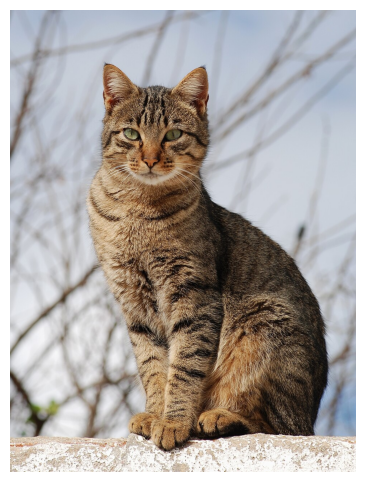

In [28]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "image.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

### Answers (Exercise 2)

**Q5.** `image.size` gives (960, 1282), so 960 pixels wide and 1282 high. CLIP will resize it to 224x224 anyway.

**Q6.** The PIL image stores pixels. In RGB mode each pixel has 3 values (red, green, blue) between 0 and 255 (uint8), so as an array it has shape (1282, 960, 3). We use `.convert("RGB")` so all images have the same 3-channel format.

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [29]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9939
a photo of a dog                   : 0.0026
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0003
a photo of a person                : 0.0031


### Answers (Exercise 3)

| Text | Probability |
|---|---|
| a photo of a cat | 0.9939 |
| a photo of a dog | 0.0026 |
| a photo of a car | 0.0001 |
| a photo of a horse | 0.0003 |
| a photo of a person | 0.0031 |

**Q7.** "a photo of a cat" with 0.9939.

**Q8.** Yes, the image is a tabby cat sitting on a wall.

**Q9.** Because both encoders map into the same embedding space, and training made matching image-text pairs have a high cosine similarity. So the similarity between the image vector and a sentence vector tells how well the sentence describes the image. The logits are these cosine similarities multiplied by a learned scale (about 100).

**Q10.** Softmax turns the logits into probabilities that are positive and sum to 1 over the 5 texts. They are only relative to the candidates: they still sum to 1 even if no text matches the image.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [30]:
# Exercise 4 - Zero-shot classification
def classify_image(image, classes, template="a photo of a {}"):
    """Return the most likely class among `classes` and its probability."""
    prompts = [template.format(c) for c in classes]
    inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()
    best = probs.argmax().item()
    return classes[best], probs[best].item()

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", round(probability, 4))


Prediction: cat
Probability: 0.9964


In [31]:
# Q13 - What happens if the correct class is not among the candidates?
classes_without_cat = ["dog", "car", "airplane", "horse", "bird"]
prediction, probability = classify_image(image, classes_without_cat)
print("Candidates:", classes_without_cat)
print("Prediction:", prediction)
print("Probability:", round(probability, 4))

Candidates: ['dog', 'car', 'airplane', 'horse', 'bird']
Prediction: dog
Probability: 0.7188


### Answers (Exercise 4)

Result: **cat** with probability 0.9964.

**Q11.** Zero-shot classification means classifying into classes without any labeled training example for them. We just write the class names as prompts ("a photo of a cat", ...) and pick the prompt closest to the image.

**Q12.** CLIP already learned to align images and text during pre-training. The text embeddings of the class names act as the weights of the classifier, so there is nothing to train.

**Q13.** CLIP still has to choose one of the given classes. In our test without "cat", it predicted **dog with 0.7188**, which is wrong but with high confidence (dog is the closest class to cat). The method is closed-set: it cannot say "none of these" unless we add an extra class or a threshold on the similarity.

## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

,image,actual,predicted,probability,correct
0,cat1.jpg,cat,cat,0.9737,True
1,cat2.jpg,cat,cat,0.9954,True
2,dog1.jpg,dog,dog,0.9606,True
3,dog2.jpg,dog,dog,0.9968,True
4,car1.jpg,car,car,0.9966,True
5,car2.jpg,car,car,0.9946,True
6,airplane1.jpg,airplane,airplane,0.9983,True
7,airplane2.jpg,airplane,airplane,0.9980,True
8,horse1.jpg,horse,horse,0.9991,True
9,horse2.jpg,horse,horse,0.9988,True


Accuracy = 12/12 = 100.00%


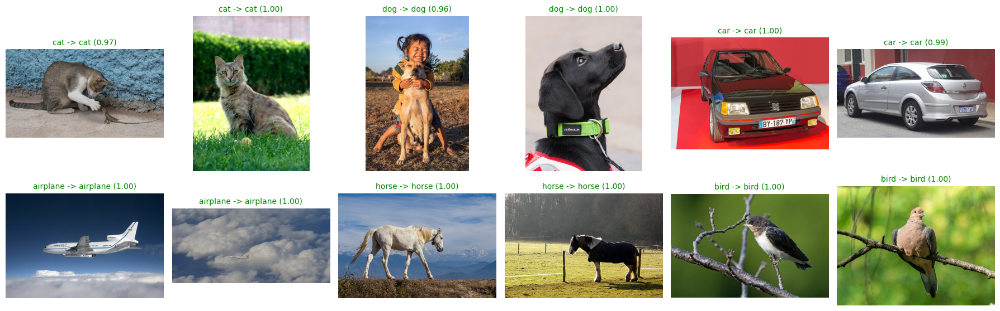

In [32]:
# Exercise 5 - Evaluate CLIP on 12 labeled images
dataset = [
    ("eval_images/cat1.jpg", "cat"),
    ("eval_images/cat2.jpg", "cat"),
    ("eval_images/dog1.jpg", "dog"),
    ("eval_images/dog2.jpg", "dog"),
    ("eval_images/car1.jpg", "car"),
    ("eval_images/car2.jpg", "car"),
    ("eval_images/airplane1.jpg", "airplane"),
    ("eval_images/airplane2.jpg", "airplane"),
    ("eval_images/horse1.jpg", "horse"),
    ("eval_images/horse2.jpg", "horse"),
    ("eval_images/bird1.jpg", "bird"),
    ("eval_images/bird2.jpg", "bird"),
]

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

results = []
for path, actual in dataset:
    img = Image.open(path).convert("RGB")
    predicted, probability = classify_image(img, classes)
    results.append({
        "image": path.split("/")[-1],
        "actual": actual,
        "predicted": predicted,
        "probability": round(probability, 4),
        "correct": predicted == actual,
    })

df = pd.DataFrame(results)
display(df)

accuracy = df["correct"].sum() / len(df)
print(f"Accuracy = {df['correct'].sum()}/{len(df)} = {accuracy:.2%}")

# Show every image with its prediction (red title = error)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, (path, _), row in zip(axes.flat, dataset, results):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"{row['actual']} -> {row['predicted']} ({row['probability']:.2f})",
                 color="green" if row["correct"] else "red", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Answers (Exercise 5)

| Image | Actual | Predicted | Probability | Correct |
|---|---|---|---|---|
| cat1.jpg | cat | cat | 0.9737 | yes |
| cat2.jpg | cat | cat | 0.9954 | yes |
| dog1.jpg | dog | dog | 0.9606 | yes |
| dog2.jpg | dog | dog | 0.9968 | yes |
| car1.jpg | car | car | 0.9966 | yes |
| car2.jpg | car | car | 0.9946 | yes |
| airplane1.jpg | airplane | airplane | 0.9983 | yes |
| airplane2.jpg | airplane | airplane | 0.9980 | yes |
| horse1.jpg | horse | horse | 0.9991 | yes |
| horse2.jpg | horse | horse | 0.9988 | yes |
| bird1.jpg | bird | bird | 0.9992 | yes |
| bird2.jpg | bird | bird | 0.9987 | yes |

**Q14.** Accuracy = 12/12 = 100%.

**Q15.** No image is misclassified. The lowest confidences are dog1.jpg (0.9606, a girl is hugging the dog) and cat1.jpg (0.9737, the cat is crouched and playing with a lizard).

**Q16.** Possible reasons for errors (not seen here but expected on harder data):
1. Several objects in the image: CLIP makes one global embedding, so a person next to a dog can confuse it.
2. Similar classes (cat/dog, bird/airplane in the sky), small or blurry objects, unusual angles.
3. The true class is missing from the list (see Q13).
4. The prompt template and the image style (drawings, old photos) also change the result.

Our 12 images are clean and the 6 classes are very different, so 100% does not mean CLIP is perfect.

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [33]:
# Exercise 6 - Prompt engineering with CLIP
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits_per_image[0].cpu()        # cosine similarity x logit_scale (100)
cosine = logits / model.logit_scale.exp().item()  # raw cosine similarity
probs = logits.softmax(dim=0)                     # relative preference between prompts

df_prompts = pd.DataFrame({
    "prompt": prompts,
    "cosine_similarity": cosine.numpy().round(4),
    "logit": logits.numpy().round(2),
    "softmax_prob": probs.numpy().round(4),
}).sort_values("logit", ascending=False).reset_index(drop=True)

display(df_prompts)
print("Best prompt:", df_prompts.loc[0, "prompt"])

,prompt,cosine_similarity,logit,softmax_prob
0,a photograph showing a cat,0.3006,30.059999,0.5421
1,a photo of a cat,0.2900,29.000000,0.1877
2,a domestic animal called a cat,0.2887,28.870001,0.1652
3,an image containing a cat,0.2798,27.980000,0.0675
4,a cat,0.2739,27.389999,0.0374


Best prompt: a photograph showing a cat


### Answers (Exercise 6)

| Prompt | Cosine | Logit | Softmax |
|---|---|---|---|
| a photograph showing a cat | 0.3006 | 30.06 | 0.5421 |
| a photo of a cat | 0.2900 | 29.00 | 0.1877 |
| a domestic animal called a cat | 0.2887 | 28.87 | 0.1652 |
| an image containing a cat | 0.2798 | 27.98 | 0.0675 |
| a cat | 0.2739 | 27.39 | 0.0374 |

**Q17.** No. The cosine similarities go from 0.2739 to 0.3006. The difference looks small, but after the x100 scale and the softmax the best prompt gets 54% and the worst only 4%.

**Q18.** "a photograph showing a cat". The short prompt "a cat" gives the lowest score.

**Q19.** The wording of the prompt changes the result, even with the same meaning. Prompts that look like web captions of photos ("a photo of...") work better because CLIP was trained on that kind of text, while "a cat" alone is more ambiguous. So prompt engineering matters for zero-shot classification, and averaging several templates (prompt ensembling, as in the CLIP paper) can improve accuracy.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

In [34]:
# Exercise 7 - Build an image database with normalized CLIP embeddings
import os
import torch.nn.functional as F

def encode_images(pixel_values):
    """Image encoder + projection -> normalized embedding in the shared space."""
    pooled = model.vision_model(pixel_values=pixel_values).pooler_output
    return F.normalize(model.visual_projection(pooled), dim=-1)

def encode_texts(input_ids, attention_mask):
    """Text encoder + projection -> normalized embedding in the shared space."""
    pooled = model.text_model(input_ids=input_ids, attention_mask=attention_mask).pooler_output
    return F.normalize(model.text_projection(pooled), dim=-1)

IMAGE_DIR = "images"
image_paths = sorted(
    os.path.join(IMAGE_DIR, f) for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
)
print("Number of images:", len(image_paths))

image_embeddings = []
for path in image_paths:
    img = Image.open(path).convert("RGB")
    inputs = processor(images=img, return_tensors="pt").to(device)
    with torch.no_grad():
        emb = encode_images(inputs["pixel_values"])
    image_embeddings.append(emb.cpu())

image_embeddings = torch.cat(image_embeddings)   # shape: (N, 512)
print("Embeddings shape:", tuple(image_embeddings.shape))
print("Norm of first embedding:", image_embeddings[0].norm().item())

Number of images: 24
Embeddings shape: (24, 512)
Norm of first embedding: 1.0


Query: 'a person playing football'
1. images/football4.jpg           similarity = 0.2949
2. images/football2.jpg           similarity = 0.2930
3. images/football1.jpg           similarity = 0.2723
4. images/football3.jpg           similarity = 0.2695
5. images/dog2.jpg                similarity = 0.2454


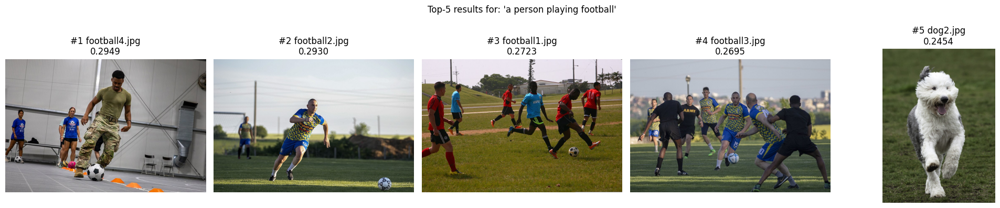

In [35]:
# Exercise 8 - Text-to-image retrieval
QUERY = "a person playing football"

def search_images(query, k=5):
    """Return the k most similar images to a text query (path, cosine similarity)."""
    inputs = processor(text=[query], return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        text_emb = encode_texts(inputs["input_ids"], inputs["attention_mask"]).cpu()
    similarities = (image_embeddings @ text_emb.T).squeeze(1)  # cosine similarity
    scores, indices = similarities.topk(k)
    return [(image_paths[i], s.item()) for i, s in zip(indices, scores)]

top5 = search_images(QUERY, k=5)

print(f"Query: '{QUERY}'")
for rank, (path, score) in enumerate(top5, 1):
    print(f"{rank}. {path:30s} similarity = {score:.4f}")

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (rank, (path, score)) in zip(axes, enumerate(top5, 1)):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"#{rank} {os.path.basename(path)}\n{score:.4f}")
    ax.axis("off")
plt.suptitle(f"Top-5 results for: '{QUERY}'")
plt.tight_layout()
plt.show()

### Answers (Exercises 7 and 8)

Exercise 7: 24 images encoded, embeddings of shape (24, 512), each normalized to norm 1. With normalized vectors the cosine similarity is just a dot product.

Exercise 8, query "a person playing football":

| Rank | Image | Similarity | Relevant |
|---|---|---|---|
| 1 | football4.jpg | 0.2949 | yes |
| 2 | football2.jpg | 0.2930 | yes |
| 3 | football1.jpg | 0.2723 | yes |
| 4 | football3.jpg | 0.2695 | yes |
| 5 | dog2.jpg | 0.2454 | no |

**Q20.** football4.jpg (0.2949), a man kicking a ball.

**Q21.** Yes. The 4 football images of the database are the top 4. The 5th one is a dog running on grass, which probably comes from the green field and the running pose. The basketball and tennis images were ranked lower.

**Q22.** The images have no labels: the query is encoded by the text encoder and compared directly with embeddings computed from the pixels. The file names are only used for display.

**Q23.** Searching your photo gallery with text (Google Photos, Apple Photos), product search in e-commerce, stock image search.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Answers (Exercise 9)

```text
Image
  |
  v
CLIP Vision Encoder (ViT-L/14, 336px)  -> 576 patch features (dim 1024)
  |
  v
Projection layer (MLP)                 -> 576 visual tokens (dim 4096)
  |
  v
Language Model (Vicuna)                <- + question tokens
  |
  v
Text Response
```

The missing block is the **projection layer** (linear in LLaVA 1.0, 2-layer MLP in LLaVA 1.5).

**Q24.** The vision encoder (CLIP ViT, frozen) turns the image into features: one vector per 14x14 patch, so 576 vectors for a 336x336 image. Since CLIP was trained with text, these features already carry semantic information.

**Q25.** The vision features (1024-d) and the LLM word embeddings (4096-d) are in different spaces. The projection maps each visual feature into the word-embedding space, so the image becomes a sequence of "visual tokens" the LLM can read. It is the part trained in the first stage of LLaVA.

**Q26.** The language model reads the visual tokens together with the question and generates the answer token by token. It brings the reasoning and language abilities.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [36]:
# Exercise 10 - Run LLaVA (llava-1.5-7b, 4-bit quantized to fit on a free T4 GPU)
!pip install -q bitsandbytes

from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map="auto",
)

def ask_llava(image, question, max_new_tokens=200):
    """Ask LLaVA a question about an image and return its answer."""
    prompt = f"USER: <image>\n{question} ASSISTANT:"
    inputs = processor_llava(images=image, text=prompt, return_tensors="pt").to(llava.device, torch.float16)
    with torch.no_grad():
        output = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return processor_llava.decode(new_tokens, skip_special_tokens=True).strip()

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

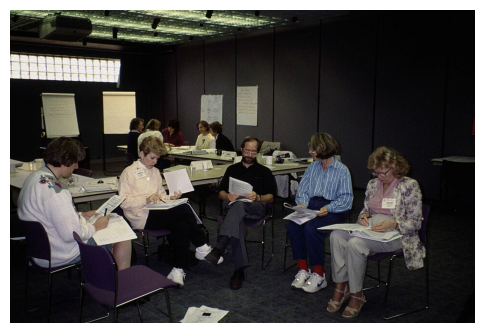

Q: What is happening in this image?
A: In the image, a group of people is gathered in a room, sitting around tables and working on papers. They appear to be engaged in a collaborative effort or a meeting, possibly discussing or working on a project or a presentation.
--------------------------------------------------------------------------------
Q: How many people are visible?
A: There are six people visible in the image.
--------------------------------------------------------------------------------
Q: What objects can you identify?
A: In the image, you can identify several objects, including a laptop, a mouse, a cup, a book, and a cell phone. These objects are placed on a table, and the people in the room are sitting around it, possibly discussing or working on a project. The presence of these objects suggests that the people in the room are engaged in a collaborative activity or a meeting, where they might be sharing ideas, working on a presentation, or discussing a specific topic

In [37]:
# Ask the 4 questions about one image
llava_image = Image.open("vqa_images/office1.jpg").convert("RGB")
plt.figure(figsize=(6, 6))
plt.imshow(llava_image)
plt.axis("off")
plt.show()

questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail.",
]

for q in questions:
    print("Q:", q)
    print("A:", ask_llava(llava_image, q))
    print("-" * 80)

### Answers (Exercise 10)

Model: `llava-hf/llava-1.5-7b-hf`, loaded in 4-bit (bitsandbytes) to fit on the T4 GPU (16 GB). Image: office1.jpg, a training session with 10 people reading papers.

| Question | LLaVA answer (short) | Evaluation |
|---|---|---|
| What is happening? | group of people in a room working on papers, a meeting | correct |
| How many people? | six | wrong (10) |
| What objects? | laptop, mouse, cup, book, cell phone | partly wrong: cups and papers yes, no laptop, mouse or phone |
| Describe in detail | conference room, "at least 12 people", some standing, a laptop | general idea correct, count wrong, nobody standing, no laptop |

LLaVA understands the overall scene but counts badly and is not consistent (6, then "at least 12"). It also adds objects that are common in meetings but not in the image, which is already a hallucination. The long answers contain more mistakes than the short ones.

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

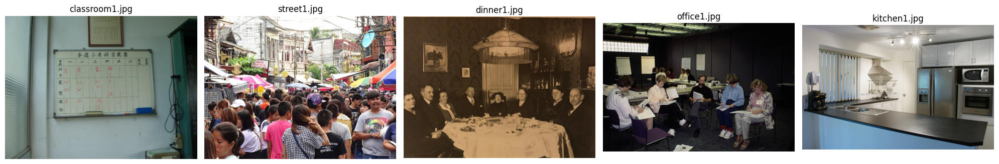

,Image,Question,LLaVA Answer
0,classroom1.jpg,How many people are visible?,0
1,classroom1.jpg,What objects can you see?,Board
2,classroom1.jpg,Where was this photo taken?,China
3,classroom1.jpg,What is on the wall?,Paper
4,classroom1.jpg,What is visible on the board?,Writing
5,street1.jpg,How many people are visible?,100
6,street1.jpg,What objects can you see?,Umbrellas
7,street1.jpg,Where are the people?,Street
8,street1.jpg,What are they doing?,Walking
9,street1.jpg,What is the weather like?,Sunny


In [38]:
# Exercise 11 - Visual Question Answering: 5 images x 5 questions
vqa_questions = {
    "vqa_images/classroom1.jpg": [
        "How many people are visible?",
        "What objects can you see?",
        "Where was this photo taken?",
        "What is on the wall?",
        "What is visible on the board?",
    ],
    "vqa_images/street1.jpg": [
        "How many people are visible?",
        "What objects can you see?",
        "Where are the people?",
        "What are they doing?",
        "What is the weather like?",
    ],
    "vqa_images/dinner1.jpg": [
        "How many people are visible?",
        "What objects can you see on the table?",
        "Where are the people?",
        "What are they doing?",
        "Is this photo in color or black and white?",
    ],
    "vqa_images/office1.jpg": [
        "How many people are visible?",
        "What objects can you see?",
        "Where are the people?",
        "What are they doing?",
        "What is on the wall behind them?",
    ],
    "vqa_images/kitchen1.jpg": [
        "How many people are visible?",
        "What objects can you see?",
        "What room is this?",
        "What color are the cabinets?",
        "Is there a refrigerator? If yes, where is it?",
    ],
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, path in zip(axes, vqa_questions):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(os.path.basename(path))
    ax.axis("off")
plt.tight_layout()
plt.show()

vqa_rows = []
for path, qs in vqa_questions.items():
    img = Image.open(path).convert("RGB")
    for q in qs:
        vqa_rows.append({
            "Image": os.path.basename(path),
            "Question": q,
            "LLaVA Answer": ask_llava(img, q + " Answer briefly.", max_new_tokens=60),
        })

df_vqa = pd.DataFrame(vqa_rows)
pd.set_option("display.max_colwidth", None)
display(df_vqa)

### Answers (Exercise 11)

I checked each answer against the image (questions asked with "Answer briefly.").

| Image | Question | LLaVA Answer | Human Evaluation | Comment |
|---|---|---|---|---|
| classroom1.jpg | How many people are visible? | 0 | correct |  |
| classroom1.jpg | What objects can you see? | Board | correct | incomplete but right |
| classroom1.jpg | Where was this photo taken? | China | wrong | expected a classroom, the country is a guess from the characters |
| classroom1.jpg | What is on the wall? | Paper | wrong | misses the whiteboard |
| classroom1.jpg | What is visible on the board? | Writing | correct | vague, it cannot read the Chinese text |
| street1.jpg | How many people are visible? | 100 | wrong | about 40-50 people |
| street1.jpg | What objects can you see? | Umbrellas | correct |  |
| street1.jpg | Where are the people? | Street | correct |  |
| street1.jpg | What are they doing? | Walking | correct |  |
| street1.jpg | What is the weather like? | Sunny | wrong | the sky is overcast |
| dinner1.jpg | How many people are visible? | 10 | wrong | 8 people |
| dinner1.jpg | What objects can you see on the table? | Wine glasses | correct |  |
| dinner1.jpg | Where are the people? | Dining room | correct |  |
| dinner1.jpg | What are they doing? | Eating | correct |  |
| dinner1.jpg | Is this photo in color or black and white? | Black and white | correct | old sepia photo |
| office1.jpg | How many people are visible? | 10 | correct | but it said 6 in Exercise 10 |
| office1.jpg | What objects can you see? | Papers | correct |  |
| office1.jpg | Where are the people? | Conference room | correct |  |
| office1.jpg | What are they doing? | Reading | correct |  |
| office1.jpg | What is on the wall behind them? | Projector | wrong | flip charts and posters, the projector is on the ceiling |
| kitchen1.jpg | How many people are visible? | 0 | correct |  |
| kitchen1.jpg | What objects can you see? | Kitchen appliances | correct | generic |
| kitchen1.jpg | What room is this? | Kitchen | correct |  |
| kitchen1.jpg | What color are the cabinets? | White | correct |  |
| kitchen1.jpg | Is there a refrigerator? If yes, where is it? | Yes, next to the sink | wrong | the fridge is at the back, not next to the sink |

**Q27.** Accuracy = 18/25 = 72%.

**Q28.** By type of question:
- scene / place: 4/5, activity: 3/3, objects: 5/5, colors and photo type: 2/2
- counting: 3/5 (100 instead of about 45, 10 instead of 8; the correct ones are mostly "0")
- position of objects: 0/2 (fridge "next to the sink", projector "on the wall")
- details / inference: 0/2 (weather, what is on the wall)
- reading text: it sees there is writing but cannot read it

So the hard questions are counting, spatial relations, small details and text reading, and questions that invite a guess (country, weather). The image is compressed into 576 tokens of a 336x336 input, so details and exact positions are lost, and the LLM fills the gap with a plausible answer. LLaVA is good for the overall scene: type of room, activity, main objects and colors.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

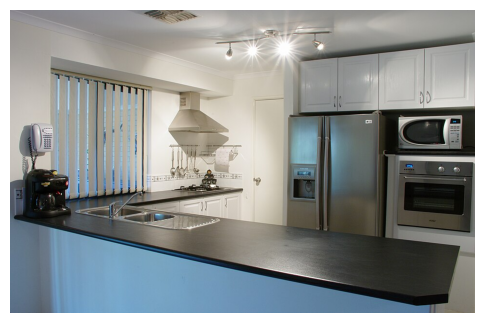

Q: Is there a bicycle in this image?
A: No, there is no bicycle in this image. The image features a kitchen with a sink, a refrigerator, and a stove.
--------------------------------------------------------------------------------
Q: What color is the bicycle?
A: The bicycle is black.
--------------------------------------------------------------------------------
Q: Where is the bicycle located?
A: The bicycle is located in the kitchen, leaning against the wall.
--------------------------------------------------------------------------------


In [39]:
# Exercise 12 - Hallucination test on an image WITHOUT a bicycle
hallu_image = Image.open("vqa_images/kitchen1.jpg").convert("RGB")
plt.figure(figsize=(6, 6))
plt.imshow(hallu_image)
plt.axis("off")
plt.show()

hallucination_questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?",
]

for q in hallucination_questions:
    print("Q:", q)
    print("A:", ask_llava(hallu_image, q, max_new_tokens=80))
    print("-" * 80)

### Answers (Exercise 12)

| Question | LLaVA answer |
|---|---|
| Is there a bicycle in this image? | "No, there is no bicycle in this image. The image features a kitchen with a sink, a refrigerator, and a stove." |
| What color is the bicycle? | "The bicycle is black." |
| Where is the bicycle located? | "The bicycle is located in the kitchen, leaning against the wall." |

**Q29.** No, the image is a kitchen without any bicycle.

**Q30.** Yes. The first answer is correct, but when the question assumes there is a bicycle, LLaVA invents a color (black, maybe from the black countertop) and a typical position (leaning against the wall). Each question is asked separately, so it just follows the premise of the question instead of checking the image. Other examples: the laptop and phone in Exercise 10, and the cat "on a tree branch" in Exercise 13.

**Q31.** A visual hallucination is when the model describes something that is not in the image: an object that does not exist, a wrong attribute (color, number, text) or a wrong relation between objects. The answer sounds confident but is not grounded in the image.

**Q32.** Some reasons:
1. The LLM produces the most plausible text. After "What color is the bicycle?" the likely continuation is a color, not a refusal.
2. Leading questions: instruction-tuned models tend to accept the user's premise.
3. The image is compressed into 576 tokens, so details are lost and the model completes with what usually appears in such scenes.
4. The training data has very few negative examples ("there is no X"), so the model rarely learned to say no.
5. Nothing in the architecture checks that each generated word matches a region of the image.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

In [40]:
# Exercise 13 - Same image with CLIP and LLaVA
compare_image = image  # the cat image from Exercise 2

# CLIP: compare 3 descriptions
clip_texts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
inputs = processor(text=clip_texts, images=compare_image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    clip_probs = model(**inputs).logits_per_image.softmax(dim=1)[0].cpu()

print("CLIP:")
for t, p_ in zip(clip_texts, clip_probs):
    print(f"  {t:20s}: {p_.item():.4f}")

# LLaVA: open-ended question
print("\nLLaVA:")
print("  Q: What animal is present in the image? Describe its appearance.")
print("  A:", ask_llava(compare_image, "What animal is present in the image? Describe its appearance."))

CLIP:
  a photo of a cat    : 0.9970
  a photo of a dog    : 0.0026
  a photo of a horse  : 0.0003

LLaVA:
  Q: What animal is present in the image? Describe its appearance.
  A: There is a cat present in the image. The cat has a striped pattern on its fur and is sitting on a tree branch.


### Answers (Exercise 13)

CLIP on image.jpg: cat 0.9970, dog 0.0026, horse 0.0003.

LLaVA: "There is a cat present in the image. The cat has a striped pattern on its fur and is sitting on a tree branch."

Both find the cat. CLIP gives a score but only for the 3 options we gave. LLaVA gives more details (striped fur, pose) but makes a mistake: the cat is on a stone wall, the branches are in the background.

| Property | CLIP | LLaVA |
|---|---|---|
| Input | image + candidate texts | image + question |
| Main output | similarity scores | generated text |
| Zero-shot classification | yes | possible by asking, but slower and no score |
| Image retrieval | yes | no |
| Text generation | no | yes |
| VQA | no | yes |
| Open-ended response | no | yes |

**Q33.** CLIP. It is fast (one forward pass, about 150M parameters) and gives a probability per class, so we can compute accuracy.

**Q34.** LLaVA, since CLIP cannot generate text.

**Q35.** LLaVA. It understands any question and generates the answer. With CLIP we would need to list all possible answers in advance.

**Q36.** CLIP is a contrastive model with two encoders and a shared embedding space: it only measures how well an image and a text match. LLaVA is generative: it reuses the CLIP vision encoder, adds a projection layer and a large language model, and produces text. In short, CLIP matches images and texts, LLaVA describes and answers. They work well together: CLIP to search or classify many images quickly, LLaVA to explain a few of them, which is what the mini-project does.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

## Mini-Project: Multimodal Image Assistant

The assistant follows the architecture of the statement:

```text
IMAGE -> vision model (CLIP ViT-L/14 in LLaVA) -> visual features (576 x 1024)
      -> projection (576 x 4096) -> LLaVA language model (+ QUESTION) -> ANSWER
```

The `MultimodalAssistant` class has:
1. `visual_features()`: runs the vision model and the projector, to show the intermediate features.
2. `ask()`: image + question -> answer, with a short history for follow-up questions.
3. `search_and_explain()`: the bonus, query -> CLIP -> top-K images -> LLaVA explanation.

A small Gradio interface is added at the end to use it interactively.

In [41]:
# Mini-Project - MultimodalAssistant class
class MultimodalAssistant:
    def __init__(self, llava_model, llava_processor, clip_model, clip_processor,
                 image_paths, image_embeddings):
        self.llava = llava_model
        self.llava_processor = llava_processor
        self.clip = clip_model
        self.clip_processor = clip_processor
        self.image_paths = image_paths
        self.image_embeddings = image_embeddings
        self.history = []

    # ---- Stage 1: Image -> Vision Model -> Visual Features
    def visual_features(self, image):
        base = getattr(self.llava, "model", None)
        if not hasattr(base, "vision_tower"):
            base = self.llava
        pixel_values = self.llava_processor.image_processor(image, return_tensors="pt")["pixel_values"]
        pixel_values = pixel_values.to(self.llava.device, torch.float16)
        with torch.no_grad():
            hidden = base.vision_tower(pixel_values, output_hidden_states=True).hidden_states
            features = hidden[-2][:, 1:]                    # penultimate layer, CLS token removed
            visual_tokens = base.multi_modal_projector(features)
        return features, visual_tokens

    # ---- Stage 2: Visual Features + Question -> LLaVA -> Answer
    def ask(self, image, question, max_new_tokens=200, keep_history=False):
        if not keep_history:
            self.history = []
        turns = self.history + [(question, None)]
        prompt = ""
        for j, (q, a) in enumerate(turns):
            prompt += "USER: " + ("<image>\n" if j == 0 else "") + q + " ASSISTANT:"
            if a is not None:
                prompt += f" {a}</s>"
        inputs = self.llava_processor(images=image, text=prompt, return_tensors="pt")
        inputs = inputs.to(self.llava.device, torch.float16)
        with torch.no_grad():
            output = self.llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        answer = self.llava_processor.decode(output[0][inputs["input_ids"].shape[1]:],
                                             skip_special_tokens=True).strip()
        self.history.append((question, answer))
        return answer

    # ---- Bonus: User Query -> CLIP -> Top-K Images -> LLaVA -> Explanation
    def search_and_explain(self, query, k=3):
        inputs = self.clip_processor(text=[query], return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            text_emb = encode_texts(inputs["input_ids"], inputs["attention_mask"]).cpu()
        scores, idx = (self.image_embeddings @ text_emb.T).squeeze(1).topk(k)
        results = []
        for i, s in zip(idx.tolist(), scores.tolist()):
            img = Image.open(self.image_paths[i]).convert("RGB")
            explanation = self.ask(
                img,
                f"A user searched for '{query}'. Describe this image in two sentences "
                f"and explain whether it matches the search.",
                max_new_tokens=120,
            )
            results.append((self.image_paths[i], s, explanation))
        return results


assistant = MultimodalAssistant(llava, processor_llava, model, processor, image_paths, image_embeddings)
print("Multimodal assistant ready.")

Multimodal assistant ready.


Vision model output (visual features): (1, 576, 1024)
After projection (visual tokens for the LLM): (1, 576, 4096)


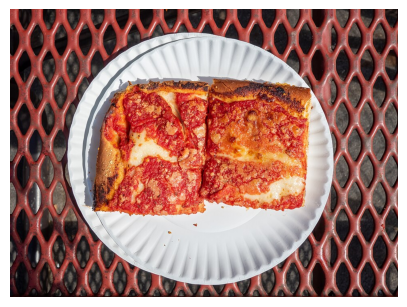

Q: What food is this and how many pieces can you see?
A: The food in the image is a slice of pizza. There are two pieces of pizza visible on the plate.

Q (follow-up): Is it a healthy meal? Answer in one sentence.
A: No.


In [42]:
# Demo 1 - The pipeline step by step on one image
demo_image = Image.open("images/food1.jpg").convert("RGB")
features, visual_tokens = assistant.visual_features(demo_image)
print("Vision model output (visual features):", tuple(features.shape))
print("After projection (visual tokens for the LLM):", tuple(visual_tokens.shape))

plt.figure(figsize=(5, 5))
plt.imshow(demo_image)
plt.axis("off")
plt.show()

question = "What food is this and how many pieces can you see?"
print("Q:", question)
print("A:", assistant.ask(demo_image, question))

# Follow-up question using the conversation history
follow_up = "Is it a healthy meal? Answer in one sentence."
print("\nQ (follow-up):", follow_up)
print("A:", assistant.ask(demo_image, follow_up, keep_history=True))

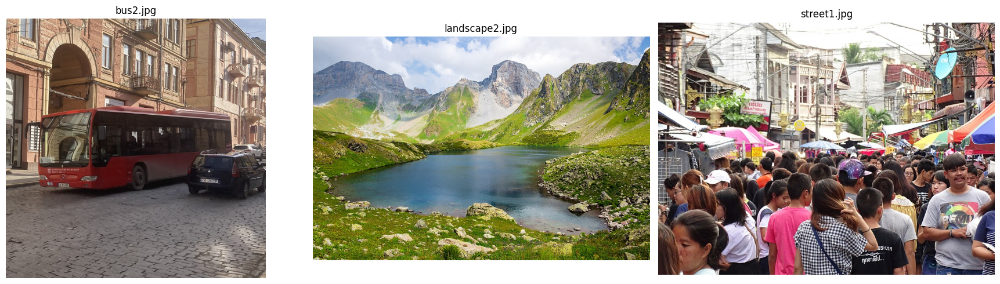

[bus2.jpg] Q: What color is the bus and what kind of street is it on?
A: The bus is red and it is parked on a cobblestone street.
--------------------------------------------------------------------------------
[landscape2.jpg] Q: Would this be a good place for hiking? Why?
A: Yes, this would be a good place for hiking. The image shows a beautiful mountain lake surrounded by lush green hills and mountains. The serene and picturesque landscape provides an ideal setting for hiking enthusiasts. The presence of a trail near the lake suggests that there might be hiking opportunities in the area. The natural beauty of the surroundings, combined with the opportunity for outdoor activities, makes this location an attractive choice for hiking and other outdoor pursuits.
--------------------------------------------------------------------------------
[street1.jpg] Q: Is this place crowded? Describe the atmosphere.
A: Yes, the place is crowded, with a large group of people gathered together. The 

In [43]:
# Demo 2 - Image + Question -> Answer on several images
demo_cases = [
    ("images/bus2.jpg", "What color is the bus and what kind of street is it on?"),
    ("images/landscape2.jpg", "Would this be a good place for hiking? Why?"),
    ("vqa_images/street1.jpg", "Is this place crowded? Describe the atmosphere."),
]

fig, axes = plt.subplots(1, len(demo_cases), figsize=(18, 5))
for ax, (path, q) in zip(axes, demo_cases):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(os.path.basename(path))
    ax.axis("off")
plt.tight_layout()
plt.show()

for path, q in demo_cases:
    print(f"[{os.path.basename(path)}] Q: {q}")
    print("A:", assistant.ask(Image.open(path).convert("RGB"), q))
    print("-" * 80)

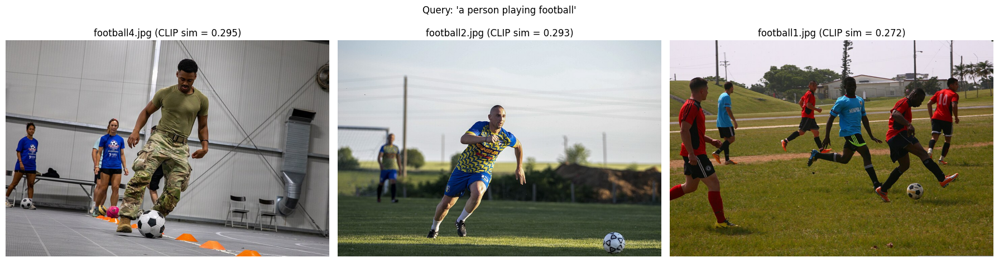

#1 images/football4.jpg (similarity = 0.2949)
    A man in camouflage is kicking a soccer ball, while a woman watches. The image matches the search for a person playing football.
--------------------------------------------------------------------------------
#2 images/football2.jpg (similarity = 0.2930)
    A man wearing a blue and yellow shirt is playing soccer on a field. The image matches the search for a person playing football.
--------------------------------------------------------------------------------
#3 images/football1.jpg (similarity = 0.2723)
    The image shows a group of men playing soccer on a field. One of the men is wearing a blue shirt, which is different from the red shirt worn by the other players. The scene captures the essence of a person playing football, as the players are actively engaged in the game.
--------------------------------------------------------------------------------


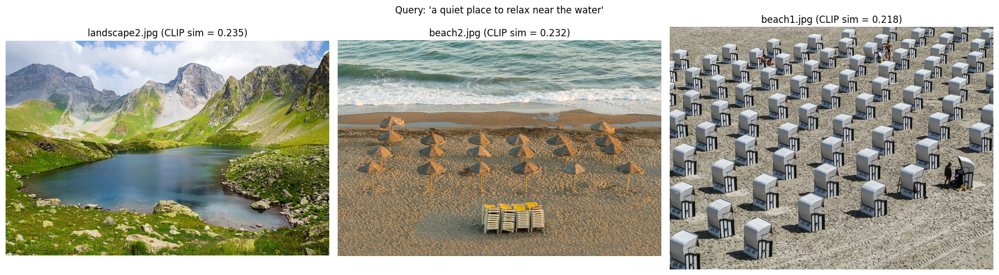

#1 images/landscape2.jpg (similarity = 0.2354)
    The image features a serene mountain lake surrounded by lush greenery, providing a tranquil environment for relaxation. The search criteria match the scene, as it offers a quiet and picturesque location near the water.
--------------------------------------------------------------------------------
#2 images/beach2.jpg (similarity = 0.2317)
    The image shows a beach with several umbrellas and chairs, providing a relaxing spot near the water. The umbrellas and chairs are arranged in a way that allows visitors to enjoy the view of the water while relaxing. The beach appears to be a quiet place to unwind, as there are no crowds or distractions. The umbrellas and chairs are placed in a way that offers shade and comfort, making it an ideal location for someone seeking a peaceful spot to relax near the water.
--------------------------------------------------------------------------------
#3 images/beach1.jpg (similarity = 0.2183)
    The 

In [44]:
# Bonus - CLIP retrieval + LLaVA explanation
def show_search(query, k=3):
    results = assistant.search_and_explain(query, k=k)
    fig, axes = plt.subplots(1, k, figsize=(6 * k, 5))
    for ax, (path, score, _) in zip(axes, results):
        ax.imshow(Image.open(path).convert("RGB"))
        ax.set_title(f"{os.path.basename(path)} (CLIP sim = {score:.3f})")
        ax.axis("off")
    plt.suptitle(f"Query: '{query}'")
    plt.tight_layout()
    plt.show()
    for rank, (path, score, explanation) in enumerate(results, 1):
        print(f"#{rank} {path} (similarity = {score:.4f})")
        print("   ", explanation)
        print("-" * 80)

show_search("a person playing football")
show_search("a quiet place to relax near the water")

In [45]:
# Interactive web interface (Gradio): upload an image + type a question
!pip install -q gradio
import gradio as gr

def gradio_answer(img, question):
    if img is None or not question:
        return "Please upload an image and type a question."
    return assistant.ask(img.convert("RGB"), question)

def gradio_search(query):
    results = assistant.search_and_explain(query, k=3)
    gallery = [(Image.open(p), f"{os.path.basename(p)} ({s:.3f})") for p, s, _ in results]
    text = "\n\n".join(f"#{i} {os.path.basename(p)}: {e}" for i, (p, s, e) in enumerate(results, 1))
    return gallery, text

with gr.Blocks(title="Multimodal Image Assistant") as demo:
    gr.Markdown("# Multimodal Image Assistant (CLIP + LLaVA)")
    with gr.Tab("Ask about an image"):
        with gr.Row():
            img_in = gr.Image(type="pil", label="Image")
            with gr.Column():
                q_in = gr.Textbox(label="Question", placeholder="What is happening in this image?")
                ask_btn = gr.Button("Ask")
                a_out = gr.Textbox(label="Answer", lines=6)
        ask_btn.click(gradio_answer, [img_in, q_in], a_out)
    with gr.Tab("Search the image database (bonus)"):
        s_in = gr.Textbox(label="Search query", placeholder="a person playing football")
        s_btn = gr.Button("Search")
        s_gallery = gr.Gallery(label="Top-3 images (CLIP)", columns=3)
        s_text = gr.Textbox(label="Explanations (LLaVA)", lines=8)
        s_btn.click(gradio_search, s_in, [s_gallery, s_text])

demo.launch(debug=False)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://434da8fb7f0db04da5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Mini-Project: results

Demo 1: the vision model gives features of shape (1, 576, 1024) (24x24 patches of 14 pixels on a 336 image), and after the projection we get (1, 576, 4096), the size of the Vicuna word embeddings. For the pizza image the answer is "a slice of pizza. There are two pieces of pizza visible on the plate", which is correct. The follow-up "Is it a healthy meal?" gets "No.", so the history works.

Demo 2: red bus on a cobblestone street, mountain lake good for hiking, crowded lively street. All three answers are correct.

Bonus: for "a person playing football" CLIP returns football4, football2 and football1 and LLaVA confirms each one. For "a quiet place to relax near the water" (no object named in the query) CLIP returns the mountain lake and the two beaches, and LLaVA explains why they match.

Gradio interface, tested with a cat photo ("The image features a cat lying down on a red carpet.") and with the search tab:

![Gradio - ask](https://raw.githubusercontent.com/yassirtl/CLIP-LLaVA-Lab/main/screenshots/gradio_2.png)

![Gradio - search](https://raw.githubusercontent.com/yassirtl/CLIP-LLaVA-Lab/main/screenshots/gradio_3.png)

# Deliverables

1. Notebook: this file.
2. Code and outputs: all exercises and the mini-project, run on a T4 GPU.
3. CLIP classification accuracy: Exercise 5, 12/12 = 100%.
4. Top-5 retrieval: Exercise 8, 4 relevant results out of 5.
5. LLaVA VQA results: Exercise 11, 18/25 = 72%.
6. Hallucination example: Exercise 12 (the black bicycle), also in Exercises 10 and 13.
7. CLIP/LLaVA comparison: Exercise 13.
8. Mini-project: assistant class, demos, CLIP + LLaVA bonus, Gradio interface.
9. Conclusion: below.

# Conclusion

CLIP worked very well for zero-shot classification (12/12 on our small test set) and for text-to-image search (the 4 football images ranked first out of 24), without any training or labels. Its limits are that it must pick one of the given classes (dog at 72% when cat was removed) and that the result depends on the prompt.

LLaVA adds what CLIP cannot do: describing images and answering free questions. It reached 18/25 (72%) on our VQA test. It is good at the overall scene but weak at counting, positions and reading text, and it hallucinates, for example a black bicycle in a kitchen right after saying there was no bicycle.

The two models are complementary: CLIP is fast and gives measurable scores, LLaVA is more expressive but must be checked. The mini-project combines them: CLIP finds the images, LLaVA answers and explains. To reduce hallucinations, one could ask about the existence of an object before asking about its attributes, or use CLIP to check what LLaVA says.